In [1]:
from pathlib import Path

import json
import joblib

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":

    PROJECT_ROOT = PROJECT_ROOT.parent


validation = pd.read_csv(

    PROJECT_ROOT

    / "reports/ml/validation_metrics.csv"
)

test = pd.read_csv(

    PROJECT_ROOT

    / "reports/ml/test_metrics.csv"
)

predictions = pd.read_csv(

    PROJECT_ROOT

    / "reports/ml/test_predictions.csv"
)

validation.round(4)

,model,accuracy,precision,recall,f1_score,tp,tn,fp,fn
0,random_forest,1.0000,1.0000,1.0000,1.0000,43,107,0,0
1,logistic_regression,0.9200,0.8444,0.8837,0.8636,38,100,7,5
2,rule_based,0.8800,0.8378,0.7209,0.7750,31,101,6,12
3,isolation_forest,0.8133,1.0000,0.3488,0.5172,15,107,0,28


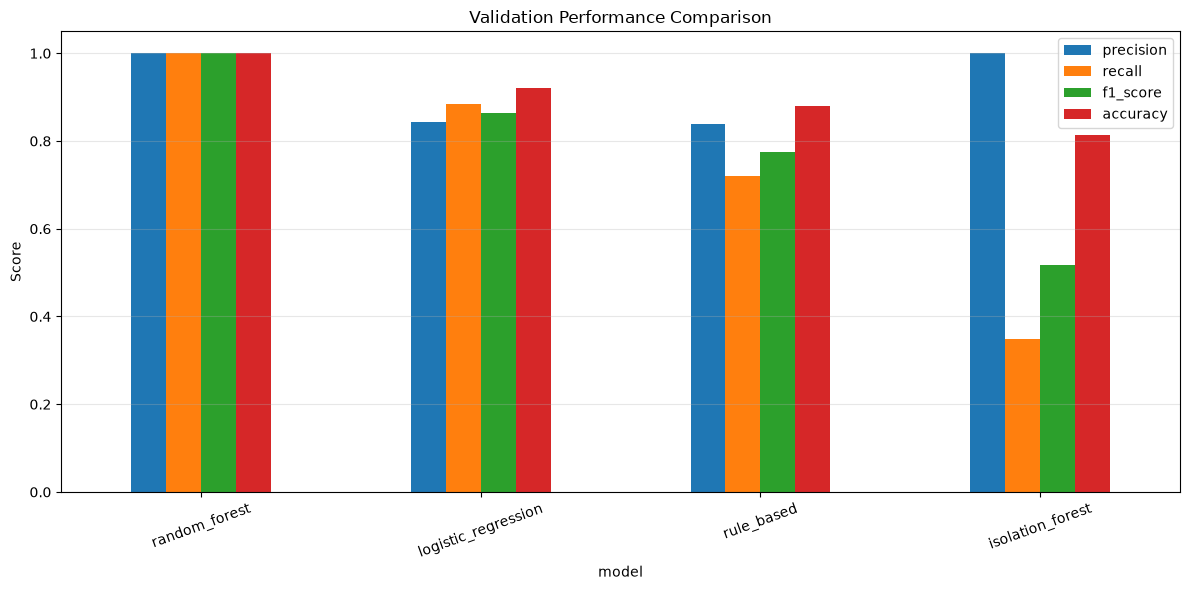

In [2]:
metrics = [
    "precision",
    "recall",
    "f1_score",
    "accuracy",
]

validation.set_index(
    "model"
)[metrics].plot(

    kind="bar",

    figsize=(12, 6),
)

plt.title("Validation Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

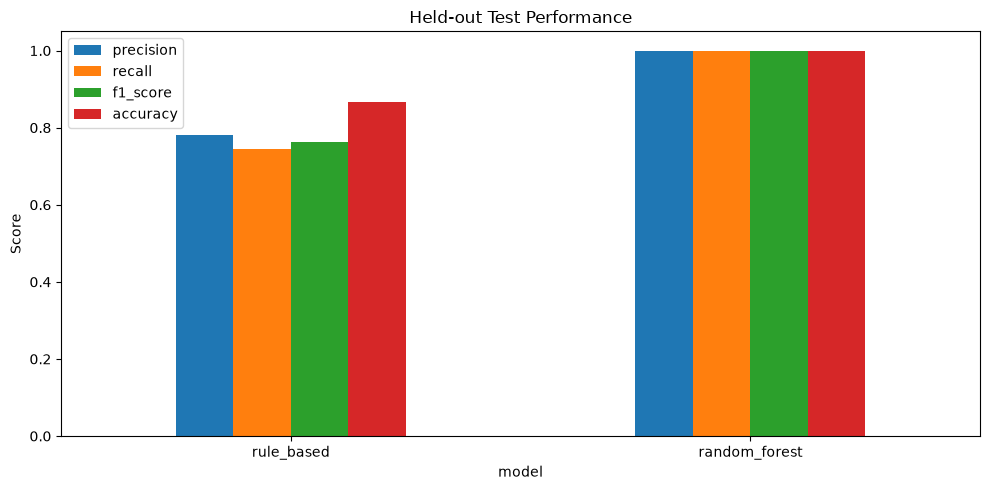

Absolute F1 improvement: 0.2381


In [4]:
test.set_index(
    "model"
)[metrics].plot(

    kind="bar",

    figsize=(10, 5),
)

plt.title("Held-out Test Performance")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

baseline_f1 = test.loc[

    test["model"] == "rule_based",

    "f1_score",

].iloc[0]


model_f1 = test.loc[

    test["model"] != "rule_based",

    "f1_score",

].iloc[0]


print(

    "Absolute F1 improvement:",

    round(model_f1 - baseline_f1, 4),
)

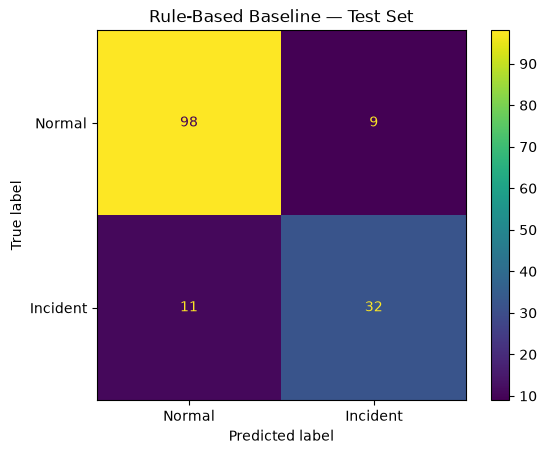

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay


ConfusionMatrixDisplay.from_predictions(

    predictions["incident_label"],

    predictions["baseline_prediction"],

    labels=[0, 1],

    display_labels=[
        "Normal",
        "Incident",
    ],
)

plt.title("Rule-Based Baseline — Test Set")

plt.show()

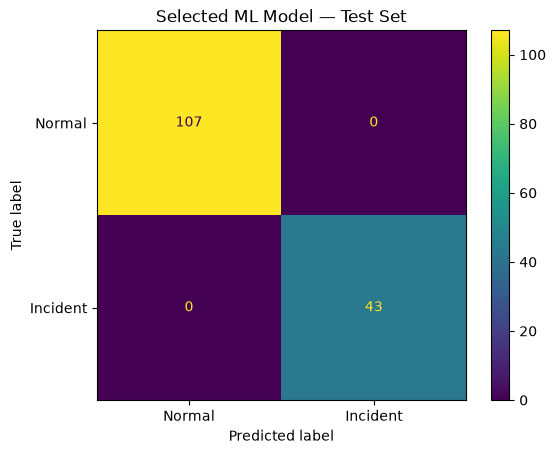

In [6]:
ConfusionMatrixDisplay.from_predictions(

    predictions["incident_label"],

    predictions["model_prediction"],

    labels=[0, 1],

    display_labels=[
        "Normal",
        "Incident",
    ],
)

plt.title("Selected ML Model — Test Set")

plt.show()

In [7]:
errors = predictions[

    predictions["incident_label"]

    != predictions["model_prediction"]
]

print(
    "Incorrect predictions:",
    len(errors),
)

errors.head(20)

Incorrect predictions: 0


,event_id,timestamp,cpu_pct,memory_pct,error_rate,p95_latency_ms,incident_label,baseline_prediction,model_prediction,model_correct


In [8]:
false_negatives = predictions[

    (predictions["incident_label"] == 1)

    &

    (predictions["model_prediction"] == 0)
]

false_negatives

,event_id,timestamp,cpu_pct,memory_pct,error_rate,p95_latency_ms,incident_label,baseline_prediction,model_prediction,model_correct


In [9]:
false_positives = predictions[

    (predictions["incident_label"] == 0)

    &

    (predictions["model_prediction"] == 1)
]

false_positives

,event_id,timestamp,cpu_pct,memory_pct,error_rate,p95_latency_ms,incident_label,baseline_prediction,model_prediction,model_correct


In [10]:
metadata = json.loads(

    (
        PROJECT_ROOT

        / "models/model_metadata.json"
    ).read_text()
)

model = joblib.load(

    PROJECT_ROOT

    / "models/incident_model.joblib"
)

print(
    "Selected model:",
    metadata["model_name"]
)

print(
    "Training strategy:",
    metadata["training_strategy"]
)

print(
    "Features:",
    metadata["features"]
)

Selected model: random_forest
Training strategy: supervised
Features: ['cpu_pct', 'memory_pct', 'error_rate', 'p95_latency_ms']


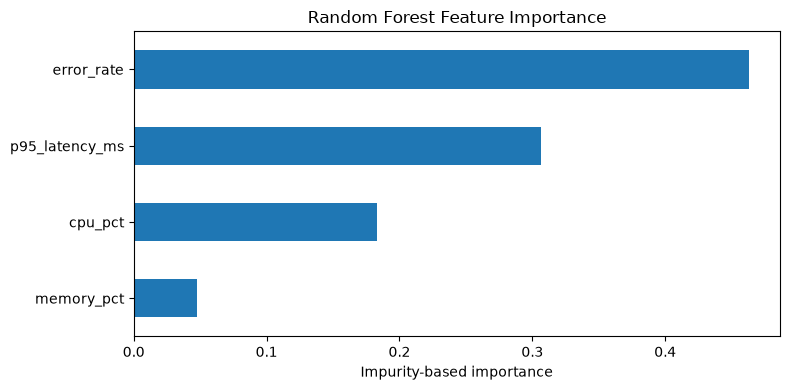

In [11]:
features = metadata["features"]

model_name = metadata["model_name"]


if model_name == "random_forest":

    importance = pd.Series(

        model.feature_importances_,

        index=features,
    )

    importance.sort_values().plot(

        kind="barh",

        figsize=(8, 4),
    )

    plt.title(
        "Random Forest Feature Importance"
    )

    plt.xlabel("Impurity-based importance")

    plt.tight_layout()

    plt.show()


elif model_name == "logistic_regression":

    coefficients = pd.Series(

        model.named_steps[
            "classifier"
        ].coef_[0],

        index=features,
    )

    coefficients.sort_values().plot(

        kind="barh",

        figsize=(8, 4),
    )

    plt.title(
        "Logistic Regression Coefficients"
    )

    plt.xlabel("Coefficient on standardized feature")

    plt.tight_layout()

    plt.show()


else:

    print(

        "Isolation Forest does not provide "
        "the same native feature-importance "
        "interface as Random Forest."
    )